# S0 — the benchmark, and what PrePPI actually contributes

Before any GPU is spent on folding, two things have to be true: the benchmark must be able to
separate interacting from non-interacting pairs, and the structural baseline we claim to beat must
be measured honestly rather than assumed.

Panels: **a** the degree confound in the negative set; **b** PrePPI `str_score` by label, which is
a tail signal and not a ranking; **c** top-k precision, the only summary that survives; **d** where
PrePPI's apparent performance comes from once membership and the experimental term are separated.

The headline of this notebook is negative and load-bearing: **PrePPI's structural score does not
rank the pairs it covers (AUROC 0.45), and almost all of its apparent skill is membership in
PrePPI at all — a threshold that contains experimental evidence.** That is the baseline the
folding arms have to be compared against, and it is a tail detector, not a ranker.

In [1]:
import warnings, sys; warnings.simplefilter("ignore")
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.gridspec as gridspec
from sklearn.metrics import roc_auc_score, average_precision_score

H = Path("/data/yzy21/yy/space_agent/structural_modelling")
RED, BLUE, GREY, INK, MUT = "#B2182B", "#2166AC", "#9A9AA2", "#1A1A1F", "#6B6B73"
plt.rcParams.update({"font.size": 9, "axes.edgecolor": INK, "axes.labelcolor": INK,
                     "xtick.color": INK, "ytick.color": INK, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 120})

D = pd.read_parquet(H / "bench" / "pairs.parquet")
PP = pd.read_csv(H / "data" / "preppi_raw" / "preppi_final600.txt", sep="\t",
                 usecols=["prot1", "prot2", "str_score", "final_score", "exp_score"],
                 low_memory=False)
pair = np.sort(PP[["prot1", "prot2"]].astype(str).to_numpy(), axis=1)
PP = PP.assign(prot_a=pair[:, 0], prot_b=pair[:, 1]).drop(columns=["prot1", "prot2"])
M = D.merge(PP, on=["prot_a", "prot_b"], how="left")
print(f"benchmark {len(D):,} rows | positives {int((D.label==1).sum()):,} | "
      f"negatives per arm {int((D.label==0).sum())//2:,}")

benchmark 970,019 rows | positives 23,659 | negatives per arm 473,180


In [2]:
# Positive-set degree per pair, which is the nuisance variable any PPI benchmark has to control.
pos = D[D.label == 1]
deg = pd.concat([pos.prot_a, pos.prot_b]).value_counts()
pairdeg = lambda sub: (sub.prot_a.map(deg).fillna(0) + sub.prot_b.map(deg).fillna(0)).to_numpy()
DEG = {"positives": pairdeg(pos),
       "random negatives": pairdeg(D[(D.label == 0) & D.neg_set.eq("random")]),
       "degree-matched negatives": pairdeg(D[(D.label == 0) & D.neg_set.eq("degmatched")])}
for k, v in DEG.items():
    print(f"{k:26s} mean {v.mean():6.2f}  median {np.median(v):5.0f}")

positives                  mean  50.51  median    37
random negatives           mean   5.08  median     1
degree-matched negatives   mean  43.96  median    36


In [3]:
# Covered pairs only: PrePPI publishes just final>=600, so everything else is PrePPI declining
# to speak. Imputing those as the floor measures membership, not structure.
C = M[M.neg_set.isin(["both", "degmatched"]) & M.str_score.notna()].copy()
covered = M[M.neg_set.isin(["both", "degmatched"])].str_score.notna()
y_all = M[M.neg_set.isin(["both", "degmatched"])].label.to_numpy()
w_all = M[M.neg_set.isin(["both", "degmatched"])].w_degmatched.to_numpy()

AUC = {
    "membership in PrePPI\n(final>=600)": roc_auc_score(y_all, covered.astype(int), sample_weight=w_all),
    "str_score\n(covered only)": roc_auc_score(C.label, C.str_score, sample_weight=C.w_degmatched),
    "final_score\n(covered only)": roc_auc_score(C.label, C.final_score, sample_weight=C.w_degmatched),
}
floor = C.w_degmatched[C.label == 1].sum() / C.w_degmatched.sum()
for k, v in AUC.items():
    print(f"{k.replace(chr(10),' '):40s} AUROC {v:.4f}")
print(f"\nweighted prevalence floor among covered pairs: {floor:.4f}")
print(f"covered positives carrying an exp_score: {C[C.label==1].exp_score.notna().mean():.3f}")
print(f"covered negatives carrying an exp_score: {C[C.label==0].exp_score.notna().mean():.3f}")

membership in PrePPI (final>=600)        AUROC 0.9111
str_score (covered only)                 AUROC 0.4459
final_score (covered only)               AUROC 0.9006

weighted prevalence floor among covered pairs: 0.0103
covered positives carrying an exp_score: 0.924
covered negatives carrying an exp_score: 0.179


In [4]:
# Top-k precision. Ties matter here: 997.34 is a single tie block that moves precision@1000
# sharply, so the tie mass is reported next to the curve.
o = np.argsort(-C.str_score.to_numpy(), kind="stable")
ys, ws, ss = C.label.to_numpy()[o], C.w_degmatched.to_numpy()[o], C.str_score.to_numpy()[o]
KS = np.unique(np.round(np.logspace(2, np.log10(len(C)), 40)).astype(int))
PREC = np.array([ws[:k][ys[:k] == 1].sum() / ws[:k].sum() for k in KS])
vals, counts = np.unique(C.str_score, return_counts=True)
print(f"str_score: {len(vals)} distinct values over {len(C):,} covered pairs "
      f"(frac {len(vals)/len(C):.4f}); largest tie block {counts.max()/len(C):.3f} of rows")
for k in (100, 1000, 5000, 20000):
    i = np.argmin(abs(KS - k))
    print(f"  top {KS[i]:6d}: precision {PREC[i]:.4f} = {PREC[i]/floor:5.1f}x the floor")

str_score: 221 distinct values over 62,708 covered pairs (frac 0.0035); largest tie block 0.181 of rows
  top    100: precision 0.1870 =  18.1x the floor
  top   1010: precision 0.2197 =  21.3x the floor
  top   5265: precision 0.0304 =   2.9x the floor
  top  19735: precision 0.0105 =   1.0x the floor


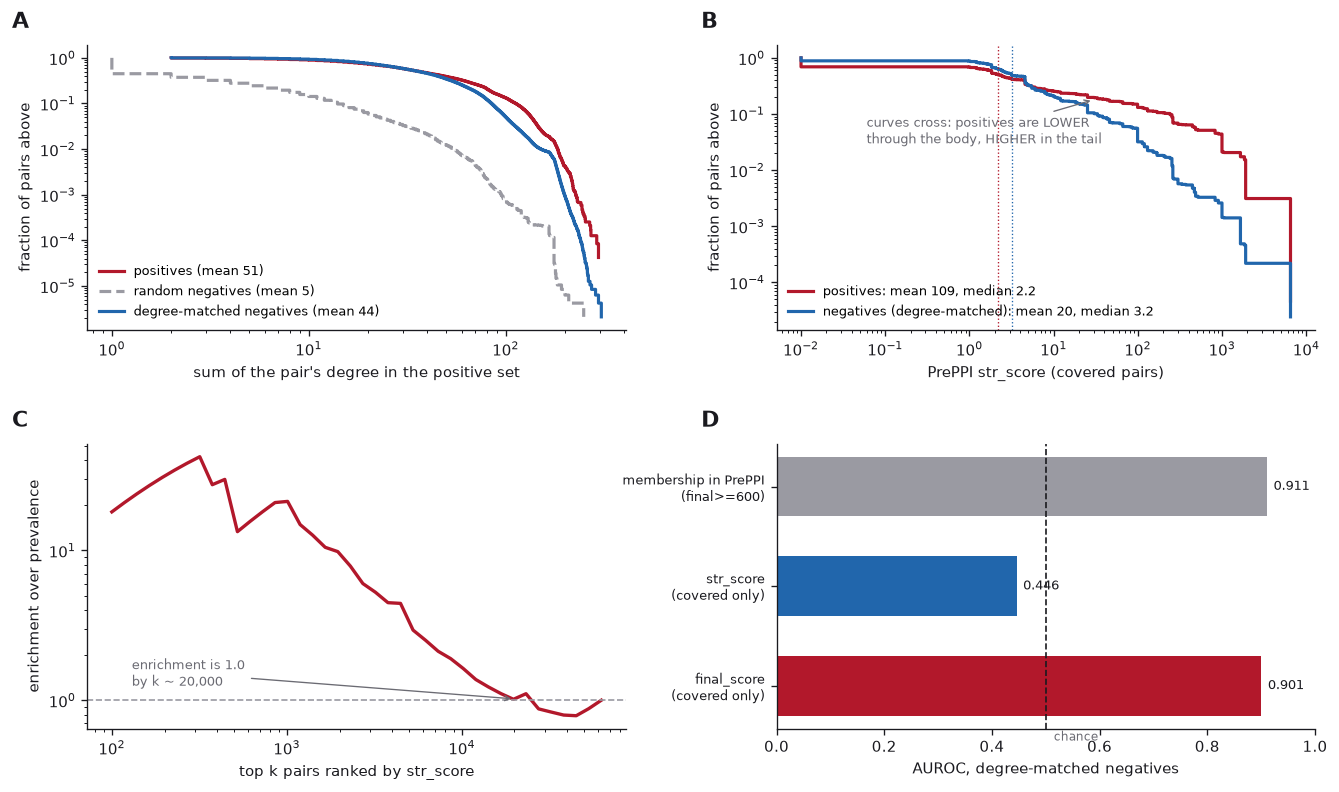

In [5]:
fig = plt.figure(figsize=(13.2, 7.4))
gs = gridspec.GridSpec(2, 2, figure=fig, hspace=.40, wspace=.28)

def survival(ax, x, col, lw=1.9, ls="-", label=None):
    """P(value > x). A histogram of these quantities is one spike at the minimum; the survival
    curve shows the whole range, and two curves CROSSING is the finding in panel b."""
    s = np.sort(np.asarray(x, float))
    ax.step(s, 1 - np.arange(len(s)) / len(s), color=col, lw=lw, ls=ls, label=label, where="post")

# a -- the degree confound
ax = fig.add_subplot(gs[0, 0])
for (k, v), col, ls in zip(DEG.items(), [RED, GREY, BLUE], ["-", "--", "-"]):
    survival(ax, np.clip(v, 1, None), col, ls=ls, label=f"{k} (mean {v.mean():.0f})")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("sum of the pair's degree in the positive set")
ax.set_ylabel("fraction of pairs above"); ax.legend(frameon=False, fontsize=7.5)
ax.text(-.14, 1.06, "A", transform=ax.transAxes, fontsize=13, fontweight="bold", color=INK)

# b -- str_score: positives have the heavier TAIL and the lower MEDIAN, so the curves cross
ax = fig.add_subplot(gs[0, 1])
for lab, col, nm in ((1, RED, "positives"), (0, BLUE, "negatives (degree-matched)")):
    s = C.loc[C.label == lab, "str_score"]
    survival(ax, np.clip(s, 1e-2, None), col,
             label=f"{nm}: mean {s.mean():.0f}, median {s.median():.1f}")
med_p = C.loc[C.label == 1, "str_score"].median()
med_n = C.loc[C.label == 0, "str_score"].median()
ax.axvline(med_p, color=RED, lw=.8, ls=":"); ax.axvline(med_n, color=BLUE, lw=.8, ls=":")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("PrePPI str_score (covered pairs)"); ax.set_ylabel("fraction of pairs above")
ax.legend(frameon=False, fontsize=7.5, loc="lower left")
ax.annotate("curves cross: positives are LOWER\nthrough the body, HIGHER in the tail",
            xy=(30, .18), xytext=(.06, .030), fontsize=7.5, color=MUT,
            arrowprops=dict(arrowstyle="->", color=MUT, lw=.8))
ax.text(-.14, 1.06, "B", transform=ax.transAxes, fontsize=13, fontweight="bold", color=INK)

# c -- the tail
ax = fig.add_subplot(gs[1, 0])
ax.plot(KS, PREC / floor, color=RED, lw=2)
ax.axhline(1, color=GREY, lw=1, ls="--")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("top k pairs ranked by str_score"); ax.set_ylabel("enrichment over prevalence")
ax.annotate("enrichment is 1.0\nby k ~ 20,000", xy=(2e4, 1.02), xytext=(1.3e2, 1.25),
            fontsize=7.5, color=MUT, arrowprops=dict(arrowstyle="->", color=MUT, lw=.8))
ax.text(-.14, 1.06, "C", transform=ax.transAxes, fontsize=13, fontweight="bold", color=INK)

# d -- where the apparent skill comes from
ax = fig.add_subplot(gs[1, 1])
names = list(AUC); vals_ = [AUC[n] for n in names]
ax.barh(range(len(names)), vals_, color=[GREY, BLUE, RED], height=.6)
ax.axvline(.5, color=INK, lw=1, ls="--")
ax.set_yticks(range(len(names))); ax.set_yticklabels(names, fontsize=7.5)
ax.set_xlabel("AUROC, degree-matched negatives"); ax.set_xlim(0, 1)
for i, v in enumerate(vals_):
    ax.text(v + .012, i, f"{v:.3f}", va="center", fontsize=7.5, color=INK)
ax.text(.515, 2.55, "chance", fontsize=7, color=MUT)
ax.invert_yaxis()
ax.text(-.14, 1.06, "D", transform=ax.transAxes, fontsize=13, fontweight="bold", color=INK)

fig.savefig(H / "results" / "s0_benchmark.png", dpi=200, bbox_inches="tight")
plt.show()

## What S0 establishes

**a** Random negatives are drawn from proteins ~10x less connected than positives (mean pair
degree 5 vs 51). The configuration-model arm restores this to 44. Any method whose score
correlates with how well studied a protein is — which includes anything MSA-based — is flattered
by the random arm, so both are carried through every later comparison.

**b** PrePPI's `str_score` has a *higher mean* (109 vs 20) and a *lower median* (2.2 vs 3.2) for
positives than negatives. It is bimodal: a minority of positives carry strong structural evidence,
most carry less than a typical negative.

**c** That is why **c** is the only honest summary. The top ~1,000 pairs are enriched 10–24x over
prevalence; by k = 20,000 the enrichment is 1.0. PrePPI's structural score is a high-precision,
very-low-recall tail detector.

**d** And the decomposition: membership in PrePPI alone scores AUROC 0.911, while `str_score`
among covered pairs scores **0.446 — below chance**. 92% of covered positives carry an
experimental term against 18% of covered negatives, so membership is largely a restatement of the
experimental evidence the labels came from. `final_score` reaches 0.90 for the same reason and is
therefore never usable as a structural baseline.

Contamination of the negatives was tested as the alternative explanation for the sub-chance
AUROC and rejected: dropping every negative with PrePPI experimental support moves AUROC to
0.421, i.e. slightly *worse*.

**Consequence for the folding arms.** The comparison metric is top-k precision and AUCPR at
1:1000, not AUROC — the same choice the RF2-PPI paper made, and panel **c** shows why it is
forced rather than stylistic. The bar to beat is ~15x enrichment in the top 1,000, achieved at
essentially zero recall.

Caveat on provenance: this is the **2016** PrePPI (the mirror's file timestamp), not the 2023
*J Mol Biol* release that rebuilds structures from the AlphaFold DB. The 2023 version may rank
differently and would need to come from the lab.